In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from pathlib import Path
import xcdat as xc
import cmasher as cmr
import xarray as xr
import sys

sys.path.append('../../functions/')
from lag_linregress import *
from monthly_departures import *
from MCA import *

# Reload edited Python modules automatically before running subsequent cells.
%load_ext autoreload
%autoreload 2

import sys

# Add the project folder only once, even if this cell is rerun.
functions_path = "/scratch/leiff/MCA/amip_clean/project_functions/"
if functions_path not in sys.path:
    sys.path.append(functions_path)

from MCA_cov import *
from significance import *
from plotting import *
from diagnostics import *
# from taylor_setup import *
from setup_diagnostic import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# %% 1. Settings: monthly regional T -> forward-year spatial T and R
import numpy as np
import xarray as xr
from pathlib import Path

fy_core = Path("/scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412")
fy_raw_root = Path("/scratch/leiff/MCA/amip_clean/data")
fy_catalog_path = fy_core / "stationarity/four_region_attribution/run_01/catalog.npy"
fy_output_dir = fy_core / "regional_forward_year/run_01"
fy_archive_path = fy_output_dir / "regional_forward_year.npy"
fy_obs_paths = {"T": fy_raw_root / "ERA5/tas_194001-202412_g025.nc",
                "R": fy_raw_root / "CERES/CERES_net_200003-202604_g025.nc"}
fy_start, fy_end, fy_window = "2000-03", "2014-12", 12
fy_experiments, fy_regions = ["historical_matched", "amip_hist"], ["WPWP", "SEP"]
fy_map_mask = None                 # Optional fixed (lat,lon) True/1 mask of RESPONSE cells.
fy_save, fy_resume = True, True
fy_save_response_series = False    # True saves raw/processed 3-D y in member checkpoints; can be large.
fy_preprocessing_tag = "monthly_detrend_after_regional_and_forward_means_v1"
fy_plot_statistic = "regression"   # Or "covariance"; both are calculated and saved.
fy_plot_vlims = None               # Or [T_limit, R_limit], shared across columns AND regions.
fy_save_figures, fy_cmap = True, "RdBu_r"

# Import/paste YOUR detrend_monthly_fast before calculating cell 4 onward.
# It must accept time-first arrays of length 167, including a partial final
# year. Both x and y start in March and are processed on the SAME 167 dates.
# Raw x(t) = area mean of absolute regional T(t); there is NO standardization.
# Raw y(t,j) = mean of field(t:t+12,j), INCLUDING t (lags 0,...,11).
# Thus 178 raw months produce 167 pairs: March 2000 through January 2014.
# The final response spans January–December 2014. Monthly samples are equally
# weighted, not day-weighted. The operation is a mean, not a 12-month sum.
# Load/plot only: run cells 1, 7, 8, 9. No raw inputs/detrending are needed then.




In [3]:
# %% 2. Small input and save helpers (the scientific calculation is in cell 3)
def fy_save_bundle(path, bundle, *, replace=False):
    """Atomic save: a stopped write cannot leave a half-written destination."""
    import os, tempfile
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".tmp", delete=False) as stream:
            temporary = Path(stream.name)
            np.save(stream, bundle, allow_pickle=True)
            stream.flush()
            os.fsync(stream.fileno())
        if replace:
            os.replace(temporary, path)
        else:
            os.link(temporary, path)  # Refuse overwriting an existing checkpoint.
    finally:
        if temporary is not None and temporary.exists():
            temporary.unlink()


def fy_fingerprint(settings):
    """Track saved numerical settings, including arrays and preprocessing code."""
    import hashlib, pickle
    return hashlib.sha256(pickle.dumps(settings, protocol=4)).hexdigest()


def fy_prepare_field(field, months, lat, lon, quantity):
    """Return (member,time,lat,lon); validate months/grid/units before loading."""
    allowed = {"T": {"K", "kelvin", "Kelvin"},
               "R": {"W m-2", "W m^-2", "W m**-2", "W/m2", "W/m^2", "W m−2"}}
    unit = field.attrs.get("units")
    if unit is not None and unit not in allowed[quantity]:
        raise ValueError(f"{field.name}: convert units {unit!r} explicitly before this analysis.")
    if unit is None:
        print(f"  {field.name}: units missing; assuming {'K' if quantity == 'T' else 'W m-2'}.")
    field = field.sel(time=slice(str(months[0]), str(months[-1])))
    actual = np.asarray(field.time.dt.year*12 + field.time.dt.month - 1)
    if not np.array_equal(actual, months.astype(int) + 1970*12):
        raise ValueError(f"{field.name}: missing, duplicate, or reordered months.")
    for dimension, expected in [("lat", lat), ("lon", lon)]:
        actual = np.asarray(field[dimension])
        if actual.shape != expected.shape or not np.allclose(actual, expected, rtol=0, atol=1e-6):
            raise ValueError(f"{field.name}: {dimension} differs from the saved regional grid.")
    extra = [d for d in field.dims if d not in ["time", "lat", "lon"]]
    if len(extra) > 1:
        raise ValueError(f"Select extra dimensions explicitly: {field.dims}")
    if extra:
        dimension = extra[0]
        if dimension not in field.coords:
            print(f"  {field.name}: member labels absent; using file positions.")
        ids = np.asarray(field[dimension]).astype(str) if dimension in field.coords else np.arange(field.sizes[dimension]).astype(str)
        field = field.rename({dimension: "member"}) if dimension != "member" else field
        field = field.assign_coords(member=ids)
    else:
        field = field.expand_dims(member=["single"])
    if not field.sizes["member"] or len(set(field.member.values)) != field.sizes["member"]:
        raise ValueError("Empty or duplicate member labels.")
    return field.transpose("member", "time", "lat", "lon")


def fy_processed(values, preprocess):
    """Use the user's monthly detrending, protecting raw inputs from mutation."""
    result = np.asarray(preprocess(values.copy()), dtype=float)
    if result.shape != values.shape or not np.isfinite(result).all():
        raise ValueError("detrend_monthly_fast must preserve shape and handle the incomplete final year.")
    # Verify the intended monthly climatology AND linear trends were removed.
    # This catches an incompatible routine without silently changing its output.
    for month in range(12):
        sample = result[month::12]
        t = np.arange(len(sample), dtype=float)
        t -= t.mean()
        mean = sample.mean(axis=0)
        slope = np.tensordot(t, sample, axes=(0, 0)) / np.sum(t*t)
        scale = np.maximum(1., np.max(np.abs(values[month::12]), axis=0))
        if np.any(np.abs(mean) > 1e-8*scale) or np.any(np.abs(slope)*len(t) > 1e-8*scale):
            raise ValueError("Expected removal of each month's mean and linear trend; check detrend_monthly_fast.")
    return result - result.mean(axis=0)  # Remove floating-point mean remnants only.




In [4]:
# %% 3. One member: raw regional x, raw forward-year y, preprocessing, then fits
def calculate_forward_year(T_raw, R_raw, weights, regions, support, preprocess, *, window=12, keep_responses=False):
    """Calculate each regional predictor against global response fields.

    T_raw/R_raw: (178,lat,lon). Paired x: (167,); paired y: (167,lat,lon).
    The returned maps are (lat,lon). No variable is divided by its temporal SD.
    Missing values on required cells raise an error, not changing area weights
    or using shorter rolling windows. Cells outside response support stay NaN.
    """
    T_raw, R_raw = [np.asarray(v, dtype=float) for v in [T_raw, R_raw]]
    weights, support = np.asarray(weights, dtype=float), np.asarray(support, dtype=bool)
    if T_raw.ndim != 3 or R_raw.shape != T_raw.shape or T_raw.shape[1:] != weights.shape or support.shape != weights.shape:
        raise ValueError("Expected matching (time,lat,lon) raw fields and (lat,lon) weights/support.")
    if not isinstance(window, (int, np.integer)) or window < 1 or window > len(T_raw):
        raise ValueError("window must be a positive integer no larger than the raw record.")
    n_pairs = len(T_raw) - window + 1
    if n_pairs < 36 or not support.any():
        raise ValueError("Need at least three samples per calendar month and nonempty response support.")
    if not np.isfinite(weights).all() or np.any(weights < 0) or weights.sum() <= 0:
        raise ValueError("Area weights must be finite, nonnegative, and nonempty.")
    masks = {}
    for region, mask in regions.items():
        mask = np.ma.asarray(mask, dtype=float).filled(np.nan)
        if mask.shape != weights.shape:
            raise ValueError(f"{region}: region shape differs from the grid.")
        masks[region] = np.isfinite(mask) & (mask != 0) & (weights > 0)
        if not masks[region].any():
            raise ValueError(f"{region}: empty temperature-source region.")
    if not masks:
        raise ValueError("Choose at least one source region.")
    needed_T = support | np.logical_or.reduce(list(masks.values()))
    if not np.isfinite(T_raw[:, needed_T]).all() or not np.isfinite(R_raw[:, support]).all():
        raise ValueError("Missing raw months on required cells; choose a fixed common response mask explicitly.")

    # Form both RAW response fields first. The view exposes (pair,lat,lon,lag);
    # averaging its last axis uses exactly 12 consecutive months, beginning at t.
    # Excluded cells use zero placeholders only while calling the user's routine.
    raw_means, responses = {}, {}
    for field_name, raw in [("T", T_raw), ("R", R_raw)]:
        work = np.where(support, raw, 0.)
        raw_means[field_name] = np.lib.stride_tricks.sliding_window_view(work, window, axis=0).mean(axis=-1)
        responses[field_name] = fy_processed(raw_means[field_name], preprocess)

    # Each region gets an instantaneous absolute-temperature area mean, trimmed
    # to the same start dates as y. Only THEN remove its monthly means/trends.
    # In particular this is NOT a mean of Zi and NOT a smoothed x predictor.
    values = {}
    for region, mask in masks.items():
        regional_weights = weights[mask] / weights[mask].sum()
        x_raw = T_raw[:n_pairs, mask] @ regional_weights
        x = fy_processed(x_raw, preprocess)
        xx = np.sum(x*x)
        # Roundoff-only residuals of a perfectly seasonal/trending x cannot
        # define a meaningful slope; fail instead of saving enormous artefacts.
        tolerance = (100*np.finfo(float).eps*max(1., np.max(np.abs(x_raw))))**2
        if xx/(n_pairs-1) <= tolerance:
            raise ValueError(f"{region}: regional x has no resolved variability after preprocessing.")
        result = {"x_raw": x_raw, "x": x, "sigma_x": np.sqrt(xx/(n_pairs-1))}
        for field_name, y in responses.items():
            # OLS y = intercept + beta*x, with common complete paired dates.
            # Sample covariance uses n-1; beta = covariance / sample variance(x).
            xy = np.einsum("t,tij->ij", x, y)
            covariance, slope = xy/(n_pairs-1), xy/xx
            intercept = y.mean(axis=0) - slope*x.mean()
            for key, value in [("covariance", covariance), ("regression", slope), ("intercept", intercept)]:
                result[f"{key}_{field_name}"] = np.where(support, value, np.nan)
            np.testing.assert_allclose(slope[support]*result["sigma_x"]**2, covariance[support], rtol=1e-10, atol=1e-12)
        values[region] = result

    # Optional large intermediates are stored ONCE per member, not repeated
    # for SEP/WPWP. Default outputs keep all fits and both regional x series.
    saved_responses = {}
    if keep_responses:
        for field_name in ["T", "R"]:
            saved_responses[f"{field_name}_raw_mean"] = np.where(support, raw_means[field_name], np.nan)
            saved_responses[field_name] = np.where(support, responses[field_name], np.nan)
    return {"values": values, "response_series": saved_responses}




In [5]:
# %% 4. Exact saved boxes, common dates, matched model list, and output definitions
if not callable(globals().get("detrend_monthly_fast")):
    raise NameError("Import/paste your detrend_monthly_fast before running the calculation cells.")
fy_catalog = np.load(fy_catalog_path, allow_pickle=True).item()  # Trusted local archives only.
fy_lat, fy_lon = [np.asarray(fy_catalog["coordinates"][d], dtype=float) for d in ["lat", "lon"]]
fy_weights = np.asarray(fy_catalog["weights"], dtype=float)
if (fy_weights.shape != (len(fy_lat), len(fy_lon)) or not np.isfinite(fy_weights).all()
        or np.any(fy_weights < 0) or fy_weights.sum() <= 0):
    raise ValueError("Invalid archived grid/weights.")
fy_weights = fy_weights / fy_weights.sum()
fy_support = fy_weights > 0
if fy_map_mask is not None:
    mask = np.ma.asarray(fy_map_mask, dtype=float).filled(np.nan)
    if mask.shape != fy_support.shape:
        raise ValueError("fy_map_mask must have the same (lat,lon) shape as the fields.")
    fy_support &= np.isfinite(mask) & (mask != 0)
fy_masks = {}
for region in fy_regions:
    mask = np.ma.asarray(fy_catalog["regions"][region], dtype=float).filled(np.nan)
    if mask.shape != fy_weights.shape:
        raise ValueError(f"{region}: mask shape differs from the saved grid.")
    fy_masks[region] = np.isfinite(mask) & (mask != 0) & (fy_weights > 0)
fy_models = {e: list(fy_catalog["model_names"][e]) for e in fy_experiments}
if any(not names or len(set(names)) != len(names) for names in fy_models.values()):
    raise ValueError("Each experiment needs a unique, nonempty model list.")
if set(fy_models["historical_matched"]) != set(fy_models["amip_hist"]):
    raise ValueError("Expected the same model population in AMIP and matched coupled.")
fy_months = np.arange(np.datetime64(fy_start, "M"), np.datetime64(fy_end, "M") + np.timedelta64(1, "M"))
if not isinstance(fy_window, (int, np.integer)) or not 1 <= fy_window <= len(fy_months):
    raise ValueError("Invalid forward-window length.")
fy_n_pairs = len(fy_months) - fy_window + 1
if fy_n_pairs < 36 or fy_months[0].astype(int) % 12 != 2:
    raise ValueError("This setup expects a March start and at least 36 paired months.")
fy_coordinates = {"lat": fy_lat, "lon": fy_lon, "raw_time": fy_months,
                   "time": fy_months[:fy_n_pairs], "response_end": fy_months[fy_window-1:]}
fy_quantity_info = {
    "x_raw": {"kind": "series", "units": "K", "meaning": "Absolute regional T at the paired start month"},
    "x": {"kind": "series", "units": "K", "meaning": "x_raw after monthly detrending/deseasonalization"},
    "sigma_x": {"kind": "scalar", "units": "K", "meaning": "Sample temporal SD of processed regional x"}}
for field_name, slope_units, cov_units, field_units in [("T", "K K-1", "K2", "K"), ("R", "W m-2 K-1", "K W m-2", "W m-2")]:
    fy_quantity_info[f"regression_{field_name}"] = {"kind": "map", "units": slope_units, "meaning": f"Processed forward-{fy_window}-month {field_name} regressed ON processed regional T"}
    fy_quantity_info[f"covariance_{field_name}"] = {"kind": "map", "units": cov_units, "meaning": f"Covariance of processed regional T with processed forward-{fy_window}-month {field_name}"}
    fy_quantity_info[f"intercept_{field_name}"] = {"kind": "map", "units": field_units, "meaning": "Intercept on the processed series; approximately zero"}

# Tag changes to preprocessing or numerical choices; mismatches cannot silently
# reuse old results. Select a new output directory for a different analysis.
import inspect
try:
    fy_preprocess_source = inspect.getsource(detrend_monthly_fast)
except (OSError, TypeError):
    fy_preprocess_source = "Source unavailable: update fy_preprocessing_tag when this function changes."
fy_settings = {"schema": "regional_forward_year_v1", "coordinates": fy_coordinates, "window": fy_window,
               "weights": fy_weights, "regions": fy_masks, "support": fy_support, "model_names": fy_models,
               "preprocessing_tag": fy_preprocessing_tag, "preprocessing_source": fy_preprocess_source,
               "save_response_series": fy_save_response_series, "ddof": 1,
               "operation_order": "Raw regional T and raw forward field means; align; monthly detrend both; covariance/OLS"}
fy_signature = fy_fingerprint(fy_settings)
if fy_save and fy_archive_path.exists():
    previous = np.load(fy_archive_path, allow_pickle=True).item()
    if not fy_resume or previous["signature"] != fy_signature:
        raise ValueError("Existing output has different settings, or resume is disabled. Choose a new output directory.")
    del previous
fy_member_values = {r: {e: {q: {} for q in fy_quantity_info} for e in fy_experiments} for r in fy_regions}
fy_observations, fy_member_ids, fy_sources = {}, {e: {} for e in fy_experiments}, {}
print(f"{len(fy_months)} raw months -> {fy_n_pairs} pairs, x dated {fy_coordinates['time'][0]}–{fy_coordinates['time'][-1]}.")
print(f"Last response: {fy_coordinates['time'][-1]}–{fy_coordinates['response_end'][-1]}.")




178 raw months -> 167 pairs, x dated 2000-03–2014-01.
Last response: 2014-01–2014-12.


In [6]:
# %% 5. Calculate observations and individual members; checkpoint each model
# Open each T/R pair once, load only this overlap period and one member at a
# time, then close both inputs automatically. T/R members align by their IDs;
# there is no attempted member pairing across coupled and AMIP experiments.
fy_jobs = [("obs", "ERA5_CERES")] + [(e, m) for e in fy_experiments for m in fy_models[e]]
for experiment, model in fy_jobs:
    print(f"{experiment} / {model}", flush=True)
    if experiment == "obs":
        paths, variables = fy_obs_paths.copy(), {"T": "t2m", "R": "toa_net_all_mon"}
    else:
        folder, tag = ("AMIP", "amip-hist") if experiment == "amip_hist" else ("HIST", "historical")
        paths, variables = {}, {"T": "tas", "R": "N"}
        for key, variable in variables.items():
            matches = sorted((fy_raw_root / folder / model).glob(f"{variable}_Amon_{model}_*{tag}*combined*187001-201412_g025.nc"))
            if len(matches) != 1:
                raise ValueError(f"{experiment}/{model}/{variable}: expected one combined file, found {matches}")
            paths[key] = matches[0]
    sources = {k: {"path": str(p), "size": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns} for k, p in paths.items()}
    checkpoint = fy_output_dir / "checkpoints" / experiment / f"{model}.npy"
    if fy_save and checkpoint.exists():
        bundle = np.load(checkpoint, allow_pickle=True).item()
        if not fy_resume or bundle["signature"] != fy_signature or bundle["sources"] != sources:
            raise ValueError(f"{checkpoint}: changed settings/inputs or resume disabled; use a new output directory.")
        print("  Reused completed model checkpoint.", flush=True)
    else:
        with xr.open_dataset(paths["T"]) as ds_T, xr.open_dataset(paths["R"]) as ds_R:
            T = fy_prepare_field(ds_T[variables["T"]], fy_months, fy_lat, fy_lon, "T")
            R = fy_prepare_field(ds_R[variables["R"]], fy_months, fy_lat, fy_lon, "R")
            if set(T.member.values) != set(R.member.values):
                raise ValueError(f"{model}: T/R member labels differ; align them explicitly.")
            R = R.sel(member=T.member.values)
            ids = np.asarray(T.member.values).astype(str)
            expected = 1 if experiment == "obs" else len(fy_catalog["member_labels"][experiment][model])
            if len(ids) != expected:
                raise ValueError(f"{model}: raw member count differs from the catalog ({len(ids)} versus {expected}).")
            collected = {r: {q: [] for q in fy_quantity_info} for r in fy_regions}
            response_series = {}
            for member, member_id in enumerate(ids):
                # This is the place to inspect a member's paired x/y or add a
                # calculation in calculate_forward_year. Raw inputs stay intact.
                result = calculate_forward_year(T.isel(member=member).values, R.isel(member=member).values,
                    fy_weights, fy_masks, fy_support, detrend_monthly_fast,
                    window=fy_window, keep_responses=fy_save_response_series)
                for region in fy_regions:
                    for quantity in fy_quantity_info:
                        collected[region][quantity].append(result["values"][region][quantity])
                if fy_save_response_series:
                    response_series[member_id] = result["response_series"]
                print(f"  member {member+1}/{len(ids)} complete", flush=True)
            bundle = {"values": {r: {q: np.stack(v) for q, v in data.items()} for r, data in collected.items()},
                       "member_ids": ids, "sources": sources, "signature": fy_signature,
                       "response_series": response_series, "experiment": experiment, "model": model}
        if fy_save:
            fy_save_bundle(checkpoint, bundle)

    # Enforce the familiar member axis, including for one-member models.
    # Observations have no model/member axis in the final observational dict.
    for region in fy_regions:
        if experiment == "obs":
            fy_observations[region] = {}
        for quantity, info in fy_quantity_info.items():
            shape = {"map": fy_weights.shape, "series": (fy_n_pairs,), "scalar": ()}[info["kind"]]
            values = np.asarray(bundle["values"][region][quantity])
            if values.shape != (len(bundle["member_ids"]),) + shape:
                raise ValueError(f"{model}/{region}/{quantity}: invalid checkpoint dimensions.")
            selected = values[:, fy_support] if info["kind"] == "map" else values
            if not np.isfinite(selected).all():
                raise ValueError(f"{model}/{region}/{quantity}: nonfinite required values in checkpoint.")
            if experiment == "obs":
                fy_observations[region][quantity] = values[0]
            else:
                fy_member_values[region][experiment][quantity][model] = values
    fy_sources.setdefault(experiment, {})[model] = sources
    if experiment != "obs":
        fy_member_ids[experiment][model] = bundle["member_ids"]
    del bundle




obs / ERA5_CERES
  member 1/1 complete
historical_matched / BCC-CSM2-MR
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CAMS-CSM1-0
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CESM2
  N: units missing; assuming W m-2.
  member 1/11 complete
  member 2/11 complete
  member 3/11 complete
  member 4/11 complete
  member 5/11 complete
  member 6/11 complete
  member 7/11 complete
  member 8/11 complete
  member 9/11 complete
  member 10/11 complete
  member 11/11 complete
historical_matched / CIESM
  N: units missing; assuming W m-2.
  member 1/3 complete
  member 2/3 complete
  member 3/3 complete
historical_matched / CNRM-CM6-1-HR
  N: units missing; assuming W m-2.
  member 1/1 complete
historical_matched / CNRM-CM6-1
  N: units missing; assuming W m-2.
  member 1/29 complete
  member 2/29 complete
  member 3/29 complete
  member 4/29 

In [7]:
# %% 6. Member -> model -> equal-model MMM; save the compact complete archive
# Average the calculated diagnostics, NOT the fields before fitting and NOT
# all members pooled together. Common support makes ordinary means appropriate:
# unsupported cells remain NaN; every included model has one equal MMM vote.
fy_model_mean_values = {r: {e: {} for e in fy_experiments} for r in fy_regions}
fy_MMM_values = {r: {e: {} for e in fy_experiments} for r in fy_regions}
for region in fy_regions:
    for experiment, models in fy_models.items():
        for quantity in fy_quantity_info:
            member_data = fy_member_values[region][experiment][quantity]
            means = {model: member_data[model].mean(axis=0) for model in models}
            fy_model_mean_values[region][experiment][quantity] = means
            fy_MMM_values[region][experiment][quantity] = np.stack([means[m] for m in models]).mean(axis=0)

fy_archive = {"member_values": fy_member_values, "model_mean_values": fy_model_mean_values,
              "MMM_values": fy_MMM_values, "observations": fy_observations, "coordinates": fy_coordinates,
              "model_names": fy_models, "member_ids": fy_member_ids, "quantity_info": fy_quantity_info,
              "regions": fy_masks, "weights": fy_weights, "response_support": fy_support,
              "settings": fy_settings, "signature": fy_signature, "sources": fy_sources,
              "metadata": {"aggregation": "Mean member diagnostics within model; equal-model arithmetic MMM",
                           "predictor": "Regional absolute T formed before preprocessing; not standardized",
                           "response": "Forward arithmetic monthly mean, lags 0 through window-1, then preprocessed",
                           "radiation": "Raw N / CERES toa_net_all_mon; stored sign unchanged",
                           "inference": "No p-values: rolling responses overlap and pairs are serially dependent",
                           "large_responses": "Optional response_series[member_id] in per-model checkpoints only"}}
if fy_save:
    fy_save_bundle(fy_archive_path, fy_archive, replace=fy_archive_path.exists())
    print(f"Saved: {fy_archive_path}")




Saved: /scratch/leiff/MCA/amip_clean/data/maps_2000_2014_covImp/overlap_core_200003_201412/regional_forward_year/run_01/regional_forward_year.npy


In [8]:
# %% 7. Load-only block and examples (no raw inputs or detrending function needed)
# Skip the reload after calculating with fy_save=False; fy_archive is in memory.
fy_archive = np.load(fy_archive_path, allow_pickle=True).item()
fy_member_values = fy_archive["member_values"]
fy_model_mean_values, fy_MMM_values = fy_archive["model_mean_values"], fy_archive["MMM_values"]
fy_observations = fy_archive["observations"]

# Member maps: (member,lat,lon); model/MMM/obs maps: (lat,lon).
# fy_member_values["SEP"]["amip_hist"]["regression_R"]["TaiESM1"]
# fy_model_mean_values["WPWP"]["historical_matched"]["covariance_T"]["TaiESM1"]
# fy_MMM_values["SEP"]["amip_hist"]["regression_T"]
# fy_observations["SEP"]["regression_R"]
# Predictor series: (member,167), or (167,) for model/MMM/obs.
# fy_member_values["SEP"]["amip_hist"]["x_raw"]["TaiESM1"]
# fy_archive["coordinates"]["time"]          # Paired predictor/response START month.
# fy_archive["coordinates"]["response_end"]  # Inclusive response END month.
# If fy_save_response_series=True when calculating:
# one = np.load(fy_output_dir/"checkpoints/amip_hist/TaiESM1.npy", allow_pickle=True).item()
# one["response_series"][one["member_ids"][0]]["T_raw_mean"]  # (167,lat,lon), before detrending.
# one["response_series"][one["member_ids"][0]]["T"]           # Same after detrending.
# Series means are descriptive only: regression(mean y on mean x) is NOT MMM regression.




In [9]:
# %% 8. Plot helper: rows T/R, columns observations/matched coupled/AMIP
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.text import Text

def plot_forward_year(archive, region, *, statistic="regression", vlims=None, cmap="RdBu_r",
                      central_longitude=210, figsize=(15, 7.5), font_scale=1., savepath=None):
    """One source region per figure; symmetric row scales shared by all columns."""
    if statistic not in ["regression", "covariance"]:
        raise ValueError("statistic must be 'regression' or 'covariance'.")
    if not np.isfinite(font_scale) or font_scale <= 0:
        raise ValueError("font_scale must be positive.")
    lat, lon = [np.asarray(archive["coordinates"][d]) for d in ["lat", "lon"]]
    groups = ["obs", "historical_matched", "amip_hist"]
    titles = {"obs": "Observations", "historical_matched": "Coupled (matched)", "amip_hist": "AMIP-hist"}
    quantities = [f"{statistic}_{field}" for field in ["T", "R"]]
    panels = np.stack([np.stack([archive["observations"][region][q] if e == "obs"
                       else archive["MMM_values"][region][e][q] for e in groups]) for q in quantities])
    if panels.shape != (2, 3, len(lat), len(lon)):
        raise ValueError("Expected two rows of three maps on the saved grid.")

    # Auto limits also include the OTHER source region, keeping the two figures
    # comparable. Only colors saturate at the 98th percentile; values are intact.
    if vlims is None:
        vlims = []
        for q in quantities:
            all_maps = [archive["observations"][r][q] if e == "obs" else archive["MMM_values"][r][e][q]
                        for r in archive["regions"] for e in groups]
            finite = np.abs(np.asarray(all_maps)[np.isfinite(all_maps)])
            if not finite.size:
                raise ValueError(f"{q}: no finite plotting values.")
            vlims.append(float(np.percentile(finite, 98)) or float(finite.max()) or 1.)
    if len(vlims) != 2 or not np.isfinite(vlims).all() or np.any(np.asarray(vlims) <= 0):
        raise ValueError("vlims must give two positive finite limits, one for T and one for R.")
    outline = np.asarray(archive["regions"][region], dtype=float)
    outline, outline_lon = add_cyclic_point(outline, coord=lon)
    fig, axes = plt.subplots(2, 3, figsize=figsize, layout="constrained",
        subplot_kw={"projection": ccrs.Robinson(central_longitude=central_longitude)})
    unit_labels = {"regression": [r"K K$^{-1}$", r"W m$^{-2}$ K$^{-1}$"],
                   "covariance": [r"K$^2$", r"K W m$^{-2}$"]}
    for row, field in enumerate(["T", "R"]):
        levels = np.linspace(-vlims[row], vlims[row], 21)
        for column, experiment in enumerate(groups):
            ax = axes[row, column]
            values, plot_lon = add_cyclic_point(panels[row, column], coord=lon)
            im = ax.contourf(plot_lon, lat, values, levels=levels, cmap=cmap,
                            transform=ccrs.PlateCarree(), extend="both")
            # Outline the actual selected grid cells, including the SEP's
            # sloping eastern boundary. This is a source box, NOT a map mask.
            ax.contour(outline_lon, lat, outline, levels=[.5], colors="black", linewidths=1.1,
                       transform=ccrs.PlateCarree(), zorder=5)
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=.5, color=".2")
            ax.set_title(f"({chr(97+3*row+column)}) {titles[experiment]} — spatial {field}", fontsize=12)
        bar = fig.colorbar(im, ax=list(axes[row]), orientation="horizontal", pad=.035, fraction=.055, shrink=.8, aspect=55)
        bar.set_label(f"{statistic.capitalize()} of forward-mean {field} on {region} T  [{unit_labels[statistic][row]}]", fontsize=11)
    c, window = archive["coordinates"], archive["settings"]["window"]
    fig.suptitle(f"{region} monthly temperature → forward {window}-month fields (lags 0–{window-1})\n"
                 f"Paired starts: {c['time'][0]}–{c['time'][-1]} ({len(c['time'])} pairs)", fontsize=15)
    fig.supxlabel("Raw regional/forward means first; monthly detrending and deseasonalization second.\n"
                  "Model panels: mean member diagnostics, then equal-model MMM. No significance stippling.", fontsize=10)
    if font_scale != 1.:
        for text in fig.findobj(match=Text):
            text.set_fontsize(text.get_fontsize()*font_scale)
    if savepath is not None:
        path = Path(savepath)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=250, bbox_inches="tight")
    return fig, axes




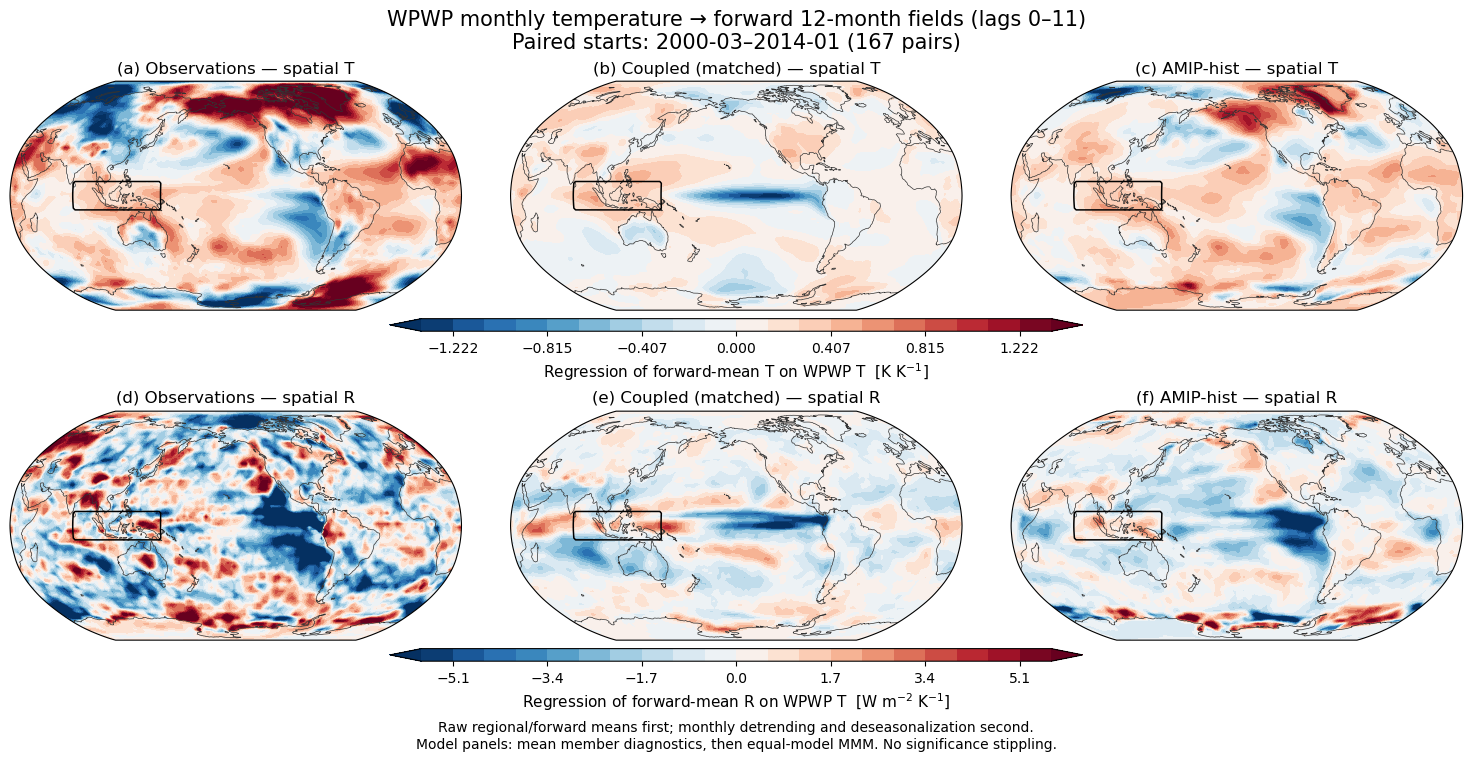

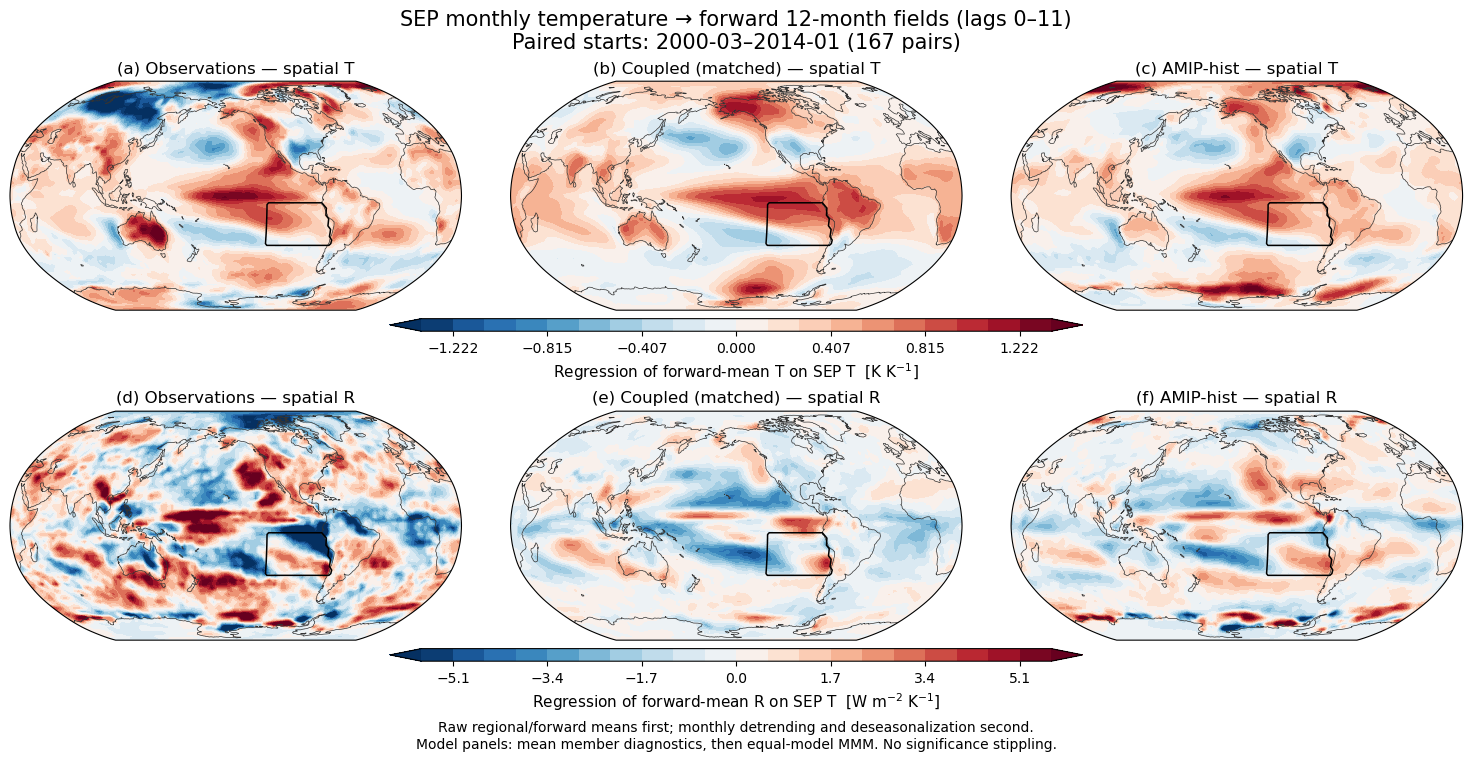

In [11]:
# %% 9. Default two figures; change the statistic to show covariance instead
fy_figures, fy_axes = {}, {}
for region in ["WPWP", "SEP"]:
    destination = fy_output_dir / f"figures/{region}_forward_year_{fy_plot_statistic}.png" if fy_save_figures else None
    fy_figures[region], fy_axes[region] = plot_forward_year(
        fy_archive, region, statistic=fy_plot_statistic, vlims=fy_plot_vlims, cmap=fy_cmap, savepath=destination)
    plt.show()
